# ACM30130 Assignment 1

**Due 2PM Monday 6 October 2025**

This assignment extends our work on the shooting method, and consists of two parts.

This assignment is motivated by [Angry Birds](https://en.wikipedia.org/wiki/Angry_Birds_(video_game)), and provides an example of where the root finding methods and IVP solvers can be combined to find an unknown parameter in a system, not just an initial condition.

The second part extends this example to where we need to solve for multiple conditions at once, using the `root` function.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

from scipy.integrate import solve_ivp
from scipy.optimize import root as solve_root, root_scalar

## Part 1: The yellow bird
In Angry Birds, the aim is to launch a projectile (a bird) at a target (a pig), just like the problem we have covered in class.
Some of the projectiles have special properties, such as the yellow bird, which can impulsively accelerate in the air at a chosen time.
You are going to model the motion of the yellow bird, and make it hit a target using the shooting method.

### a) Solve and plot the projectile motion for given initial conditions and boost time

- Use `solve_ivp` to integrate the equations of motion $$
\ddot{x} = 0, \quad \ddot{y} = -g$$ from $t=0$ to $t=0.5$ with an initial position $(x,y)=(0,0)$ and initial velocity $(\dot{x}, \dot{y}) = (5, 5)$. Use $g=9.81$.
- Taking the values obtained at $t=0.5$, modify the velocity such that the speed is increased to 15, but the direction of motion remains the same.
- Use `solve_ivp` to integrate the same equations from this new state at $t=0.5$ up to $t=1.1$.
- Plot the projectile motion $y(x)$, only showing data where $y>0$.

Q.1(a)

In [ ]:
# Define a function that returns the derivatives of the system
def dy_dt(t, y):
  x_position, y_position, x_velocity, y_velocity = y
  dxdt = x_velocity
  dydt = y_velocity
  dx_velocity_dt = 0
  dy_velocity_dt = -9.81
  return [dxdt, dydt, dx_velocity_dt, dy_velocity_dt]

# Set the initial conditions and the start/end times
initial_conditions = [0,0,5,5]
t0 = 0
tf = 0.5

# Solve the system
solution = solve_ivp(dy_dt, [t0, tf], initial_conditions)







Q1.(a)

In [ ]:
# Take the values obtained at t = 0.5
v_x = solution.y[2, -1] # Extracts the x-velocity at the final time point
v_y = solution.y[3, -1] # Extracts the y-velocity at the final time point

# Now modify the velocity such that the speed is increased to 15
# Compute the original speed using the speed formula
original_speed = np.sqrt(v_x**2 + v_y**2)

# Determine the scale factor to increase the speed to 15 m/s while maintaining the same direction
scale_factor = 15 / original_speed

# Scale the original velocity components
new_v_x = scale_factor * v_x
new_v_y = scale_factor * v_y




Q1.(a)

In [ ]:
# Integrate the new equations from this state - t = 0.5  up to t = 1.1

# Extract the end positions at t = 0.5
x_position1 = solution.y[0,-1]
y_position1 = solution.y[1,-1]

# Determine the new initial conditions
new_initial_conditions = [x_position1,y_position1,new_v_x,new_v_y]
new_t0 = 0.5 # Updated starting time
new_tf = 1.1 # Updated ending time

# Solve the new system
new_solution = solve_ivp(dy_dt, [new_t0, new_tf], new_initial_conditions)

Q1. (a)

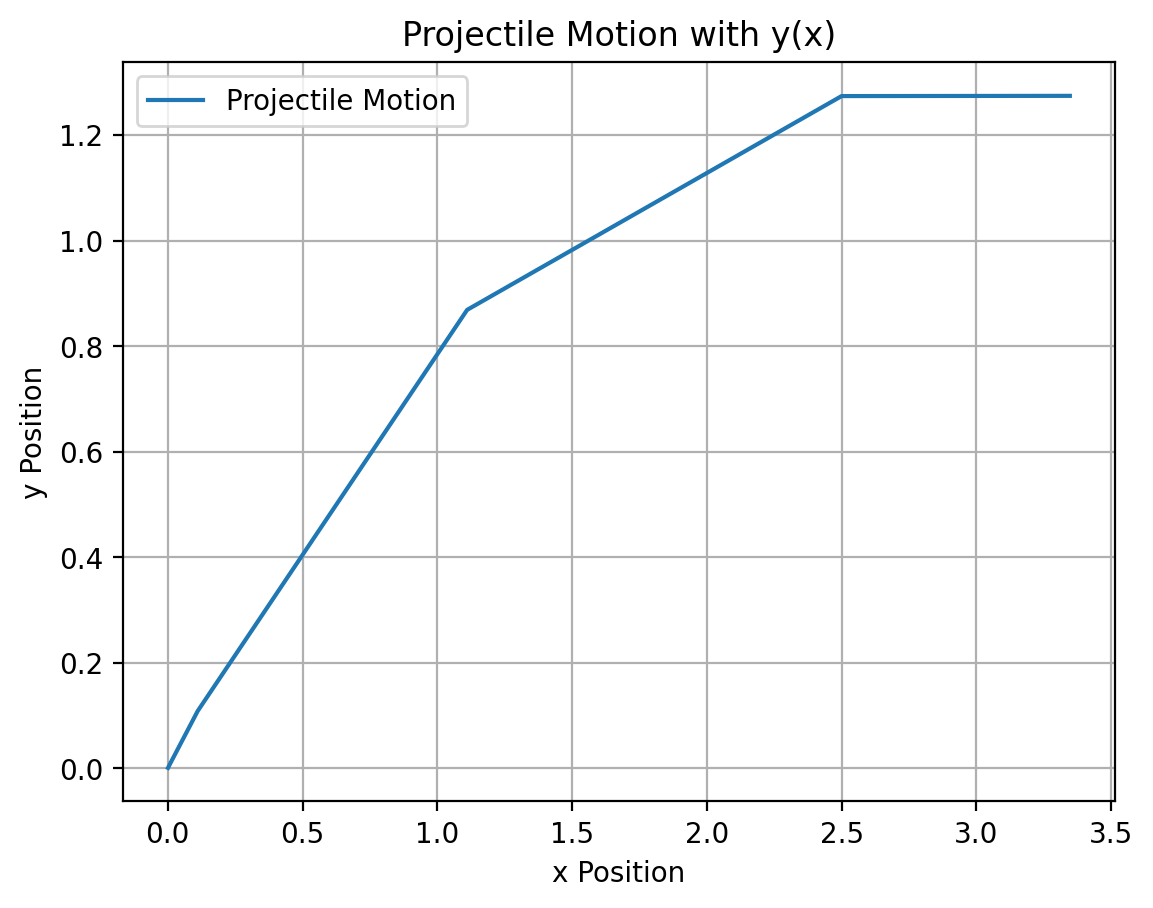

In [ ]:
# Combine both solutions to plot y(x), the entire trajectory
combined_x = np.concatenate((solution.y[0], new_solution.y[0]))
combined_y = np.concatenate((solution.y[1], new_solution.y[1]))

# Ensure that data where y > 0 is only showed - to keep it above ground
condition = combined_y > 0
filtered_x = combined_x[condition]
filtered_y = combined_y[condition]

# Plot the combined trajectory
plt.plot(filtered_x, filtered_y, label='Projectile Motion')
plt.xlabel('x Position')
plt.ylabel('y Position')
plt.title('Projectile Motion with y(x)')
plt.legend()
plt.grid()
plt.show()

### b) Define a function of the boost time that equals zero when a target is hit
Consider the same initial conditions
$$
x(0)=0, \quad \dot{x}(0)=5, \quad y(0)=0, \quad \dot{y}(0)=5
$$
but now let the time at which the speed is modified be a free parameter $t_\mathrm{boost}$.
We are aiming to hit a target at $(x,y) = (9, 0.4)$

Define a Python function that

- takes $t_\mathrm{boost}$ as its (only) input
- solves the IVP from $t=0$ up to $t=t_\mathrm{boost}$
- increases the speed of the projectile to 15
- solves the IVP from $t=t_\mathrm{boost}$ up to $t=t_f$ (where $t_f$ can be determined as when $x(t)=x_\mathrm{target}=9$)
- returns the difference between $y(t_f)$ and $y_\mathrm{target}=0.4$

Q1.(b)

In [ ]:
# Again define a function that returns the derivatives of the system
def dy_dt(t, y):
  x_position, y_position, x_velocity, y_velocity = y
  dxdt = x_velocity
  dydt = y_velocity
  dx_velocity_dt = 0
  dy_velocity_dt = -9.81
  return [dxdt, dydt, dx_velocity_dt, dy_velocity_dt]

# Define a function that has tboost as its input and solves the ivp from t = 0 to tboost
# To return the difference in vertical height between the projectile and the target (9,0.4) at a given time
# The function will equal zero when the target is hit

def target_hit(t_boost):
  # Establish the target as x and y components
  x_target = 9
  y_target = 0.4

  # Define the initial conditions and starting time
  initial_conditions= [0,0,5,5]
  t0 = 0

  # Integrate the original equations of motion from t0 to tboost
  solution_a = solve_ivp(dy_dt, [t0, t_boost], initial_conditions)

  # Extract the projectiles position and velocity at the end (at t = tboost)
  x_position2 = solution_a.y[0,-1] # -1 index gives final values
  y_position2 = solution_a.y[1,-1] # Exrtacs y_position at the final time point
  v_x2 = solution_a.y[2, -1] # Extracts the x-velocity at the final time point
  v_y2 = solution_a.y[3, -1] # Extracts the y-velocity at the final time point

  # Increase the speed to 15 m/s (apply the speed boost)
  original_speed = np.sqrt(v_x2**2 + v_y2**2)
  scale_factor = 15 / original_speed # Maintains direction
  new_v_x2 = scale_factor * v_x2 # New x-velocity with boost
  new_v_y2 = scale_factor * v_y2 # New y-velocity with boost

  # Update the intial conditons to account for the boost
  new_initial_conditions1 = [x_position2,y_position2,new_v_x2,new_v_y2]

  # Define an event function which will stop the integration once x = x_target = 9
  def target_event(t, y):
    return y[0] - x_target # Integration stops once the difference = 0
  target_event.terminal = True
  target_event.direction = 1 # Trigger event only when x is increasing

  # Solve the IVP from tboost to tf by integrating onward from tboost
  # End the integration in accordance with the event function above
  # Add 5 to tboost to ensure enough time has lapsed for the target to be reached
  final_time = 5 + t_boost
  final_solution = solve_ivp(dy_dt,[t_boost, final_time], new_initial_conditions1,
  events = target_event)

  # Determine the vertical distance from the target at once the horizontal component is reached
  # Extract the final vertical position when x = x_target
  y_at_target = final_solution.y[1,-1]

  # Return the difference in the vertical distance between the projectile and the target
  return y_at_target - y_target














### c) Plot the output of this function for a range of $t_\mathrm{boost}$ and use `root_scalar` to find the appropriate root

- Plot $F(t_\mathrm{boost})$ for $t_\mathrm{boost}\in[0,2]$ where $F$ is your function from part b).
- Use `root_scalar` to find the value of $t_\mathrm{boost}$ that hits the target
- Plot the trajectory $y(x)$ for this value, including the target as a circular marker on the plot

Q1.(c)

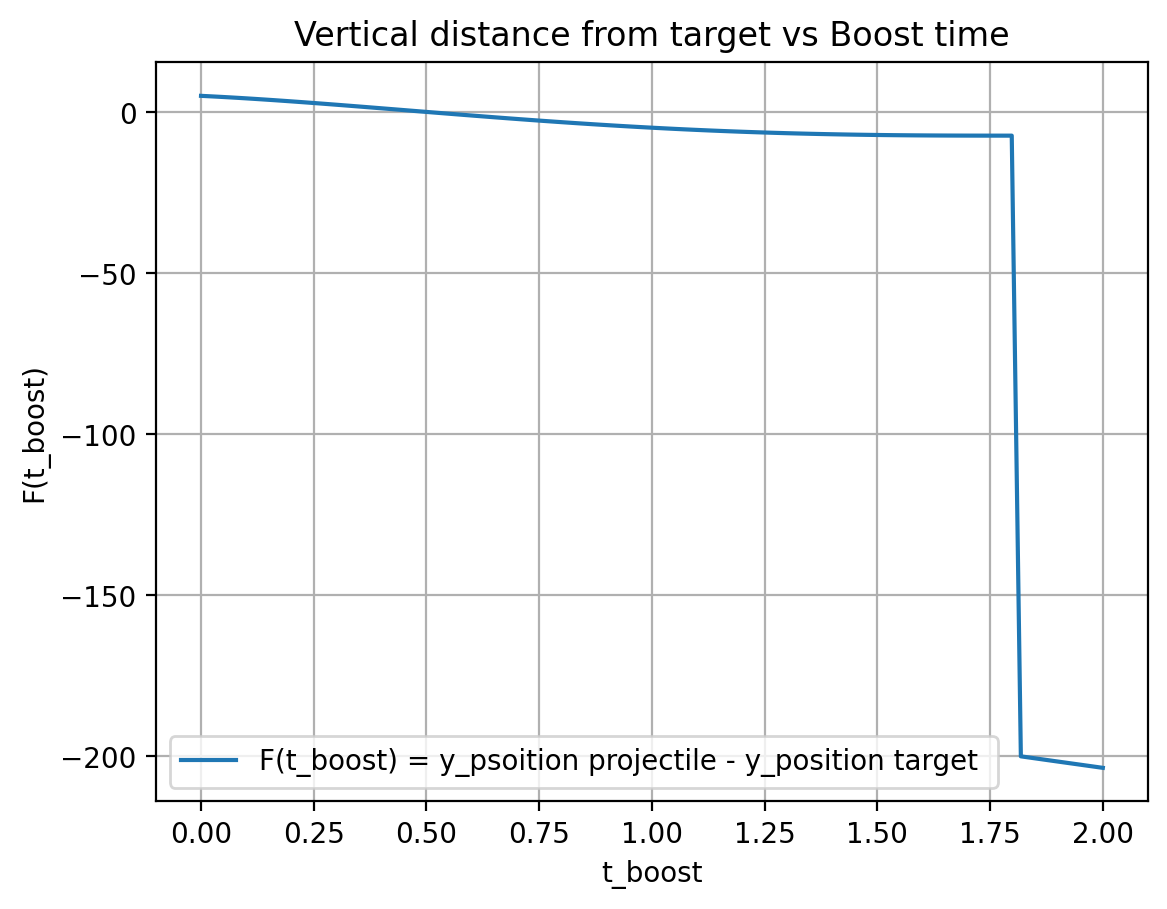

The value of t_boost that hits the target is: 0.5067367141399068


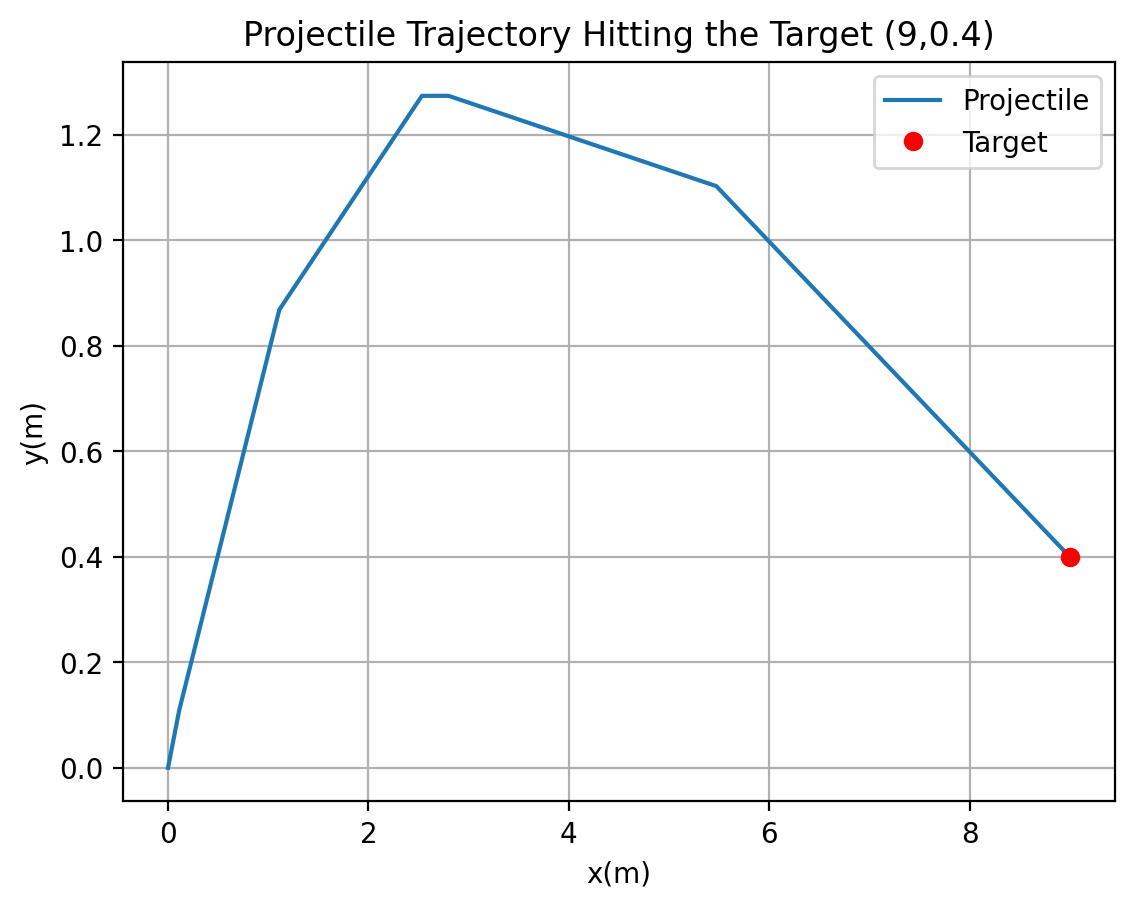

In [ ]:
# Define a range of t values from 0 to 2
t_values = np.linspace(0,2,100)
# Define F(t_values) for this range
F_values = [target_hit(t) for t in t_values]

# Plot the function
plt.plot(t_values, F_values, label = 'F(t_boost) = y_psoition projectile - y_position target ')
plt.xlabel('t_boost')
plt.ylabel('F(t_boost)')
plt.title('Vertical distance from target vs Boost time')
plt.legend()
plt.grid()
plt.show()


# Use root_scalar to find the tboost that hits the target
root = root_scalar(target_hit, bracket=[0,2])
tboost = root.root
print("The value of t_boost that hits the target is:", root.root)

# Plot the trajectory y(x) for this value, including the target as a circular marker on the plot
# Combine both solutions to plot y(x), the entire trajectory
# Recall the intial integrations
solution_a = solve_ivp(dy_dt, [t0, tboost], initial_conditions)


# Extract the projectiles position and velocity at the end (at t = tboost)
x_position2 = solution_a.y[0,-1] # -1 index gives final values
y_position2 = solution_a.y[1,-1] # Exrtacs y_position at the final time point
v_x2 = solution_a.y[2, -1] # Extracts the x-velocity at the final time point
v_y2 = solution_a.y[3, -1] # Extracts the y-velocity at the final time point

# Increase the speed to 15 m/s (apply the speed boost)
original_speed = np.sqrt(v_x2**2 + v_y2**2)
scale_factor = 15 / original_speed # Maintains direction
new_v_x2 = scale_factor * v_x2 # New x-velocity with boost
new_v_y2 = scale_factor * v_y2 # New y-velocity with boost

# Update the intial conditons to account for the boost
new_initial_conditions1 = [x_position2,y_position2,new_v_x2,new_v_y2]

# Define an event function which will stop the integration once x = x_target = 9
# Set x_target
x_target = 9
def target_event(t, y):
  return y[0] - x_target # Integration stops once the difference = 0
target_event.terminal = True
target_event.direction = 1 # Trigger event only when x is increasing

# Run the integrations from the boost until the target is reached
final_solution = solve_ivp(dy_dt, [tboost, tboost + 5], new_initial_conditions1,
                           events = target_event)

# Combine both solutions to plot y(x), the entire trajectory
combined_x1 = np.concatenate((solution_a.y[0],final_solution.y[0]))
combined_y1 = np.concatenate((solution_a.y[1],final_solution.y[1]))

# Plot the trajectory including a circle for the target mark
plt.plot(combined_x1, combined_y1, label = 'Projectile')
plt.plot(9, 0.4, 'ro', label = 'Target') # Target Mark
plt.xlabel('x(m)')
plt.ylabel('y(m)')
plt.title(f'Projectile Trajectory Hitting the Target (9,0.4)')
plt.legend()
plt.grid()
plt.show()






## Part 2: Angry Birds in 3-D

We'll now make things a little more complicated by considering the same problem in 3-D and including air resistance and a crosswind.
The governing equations are now
$$
\begin{align}
\ddot{x} &= -c\dot{x}, \\ \ddot{y} &= -c\dot{y} - g, \\ \ddot{z} &= -c(\dot{z} - 1).
\end{align}
$$

The projectile still starts at the origin $(x,y,z)=(0,0,0)$ and the target will be in the same location $(x,y,z) = (9,0.4,0)$.
The intial velocity of the projectile can be expressed as
$$
\dot{x}(0) = v_0 \cos\theta \cos\phi, \qquad
\dot{y}(0) = v_0 \sin\theta, \qquad
\dot{z}(0) = v_0 \cos\theta \sin\phi.
$$
where we fix the initial speed as $v_0=7$ and the elevation angle as $\theta=\pi/4$.
In the governing equations, take $c=1$.

We can express this as a problem of three conditions $(x,y,z)|_{t=t_f}=(9, 0.4, 0)$ for three unknowns:

- the horizontal angle $\phi$,
- the boost time $t_\mathrm{boost}$,
- the final time of integration $t_f$.

Set up the problem as in part 1, but now with a vector function to impose these three boundary conditions at the target.
Plot the resulting trajectory, either as 2 subplots with top-down and side-on views, or as a [3-D line plot](https://matplotlib.org/stable/gallery/mplot3d/lines3d.html)

The value of the horizontal angle phi which is needed to hit the target is: -0.09758262422450058
The time to boost the projectile in order to hit the target is: 0.3382914609572122
The time at which the projectile hits the target is: 1.0642836707795758


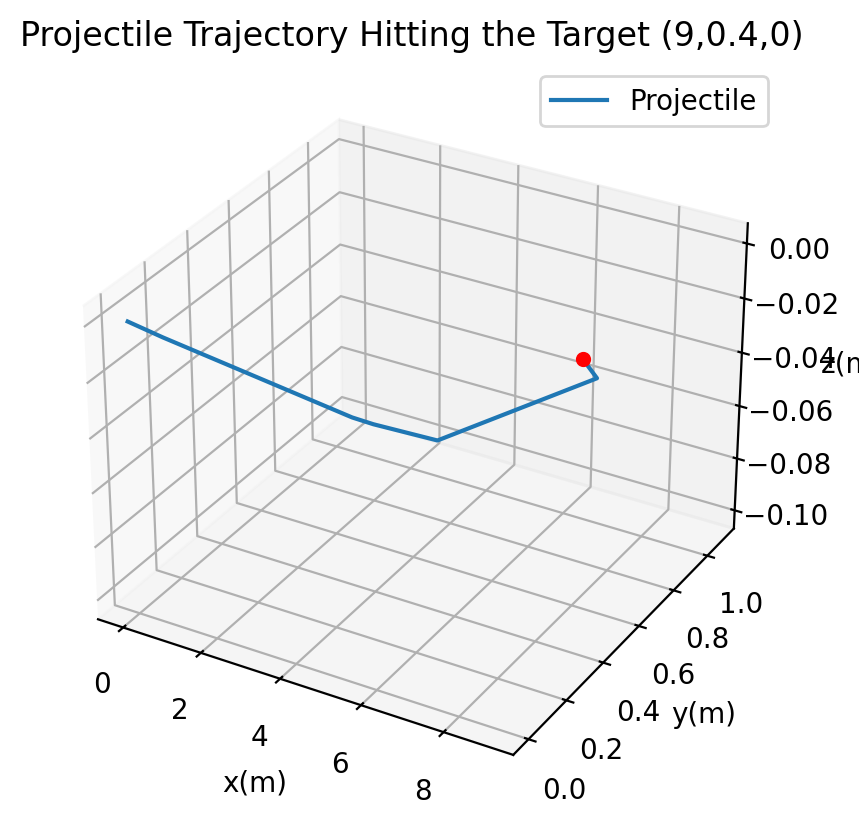

In [ ]:
# Define the constants
g = 9.81 # Gravity
c = 1 # Air resitance coefficient
v0 = 7 # Initial speed
theta = np.pi/4 # Angle of elevation

# Determine co-ordinates of the target
target_vector = np.array([9,0.4,0])

# Define a function that returns the derivatives of the system
# This will compute the derivatives of position and velocity in 3D with air resistance & crosswind
def dy_dt1(t,y):
  x_pos, y_pos, z_pos, x_vel, y_vel, z_vel = y

  # Derivatives of positions
  dxdt = x_vel
  dydt = y_vel
  dzdt = z_vel
  # Derivatives of velocities
  dxv_dt = -c * x_vel
  dyv_dt = -c * y_vel - g
  dzv_dt = -c * (z_vel - 1)
  return [dxdt, dydt, dzdt, dxv_dt, dyv_dt, dzv_dt]

# Define a function to determine the initial 3D velocity components
def initial_v(phi):
  vxi = v0 * np.cos(theta) * np.cos(phi) # x velocity component
  vyi = v0 * np.sin(theta) # y velocity component
  vzi = v0 * np.cos(theta) * np.sin(phi) # z velocity component
  return [vxi, vyi, vzi]

# Define a function that outputs the difference between the projectile position and the  moving target
def target_3d(vector):
  phi, tboost1, tfinal = vector

  # Define the initial state consisting of the projectiles position and velocity at t0
  initial_state = [0,0,0] + initial_v(phi)
  t0 = 0

  # Integrate from the start up until the boost (before tboost)
  initial_solution = solve_ivp(dy_dt1, [t0, tboost1], initial_state)

  # Extract both the position and velocity at the time of the boost (tboost)
  # -1 index extracts the last value
  x_pos1 = initial_solution.y[0,-1] # x position at tboost
  y_pos1 = initial_solution.y[1,-1] # y position at tboost
  z_pos1 = initial_solution.y[2,-1] # z position at tboost
  x_vel1 = initial_solution.y[3,-1] # x velocity at tboost
  y_vel1 = initial_solution.y[4,-1] # y velocity at tboost
  z_vel1 = initial_solution.y[5,-1] # z velocity at tboost

  # Increase the speed to 15 m/s (apply the boost)
  original_speed = np.sqrt(x_vel1**2 + y_vel1**2 + z_vel1**2)
  scale_factor = 15 / original_speed # Maintains direction
  vx_boost = scale_factor * x_vel1
  vy_boost = scale_factor * y_vel1
  vz_boost = scale_factor * z_vel1

  # Update the initial conditions to account for the boost
  new_ic = [x_pos1, y_pos1, z_pos1, vx_boost, vy_boost, vz_boost]

  # Integrate from tboost to tend
  boosted_solution = solve_ivp(dy_dt1, [tboost1, tfinal], new_ic)

  # Extract each component positions at tfinal
  x_pos2 = boosted_solution.y[0,-1]
  y_pos2 = boosted_solution.y[1,-1]
  z_pos2 = boosted_solution.y[2,-1]

  # Return the difference between the projectile position and the target in 3D, at tfinal
  return np.array([x_pos2, y_pos2, z_pos2])- target_vector

# Solve for the system
# That is find phi, tboost1 and tf values which causes the projectile to hit the target
# Make an initial guess for each input
guess = [0.1,0.5,2.5]
solved = root(target_3d, guess)
# Exctract these solutions
phi = solved.x[0]
tboost1 = solved.x[1]
tfinal = solved.x[2]

# Print results
print("The value of the horizontal angle phi which is needed to hit the target is:" , phi)
print("The time to boost the projectile in order to hit the target is:", tboost1)
print("The time at which the projectile hits the target is:", tfinal)

# Integrate entire trajectory (from 0 to tboost and tboost to tfinal)
# Time points for smooth plotting
t_points = np.linspace(0, tfinal, 100)

# From 0 to tboost1
initial_state = [0,0,0] + initial_v(phi)
initial_solution = solve_ivp(dy_dt1, [0, tboost1], initial_state)

# Extract both the position and velocity at the time of the boost (tboost)
# -1 index extracts the last value
x_pos1 = initial_solution.y[0,-1] # x position at tboost
y_pos1 = initial_solution.y[1,-1] # y position at tboost
z_pos1 = initial_solution.y[2,-1] # z position at tboost
x_vel1 = initial_solution.y[3,-1] # x velocity at tboost
y_vel1 = initial_solution.y[4,-1] # y velocity at tboost
z_vel1 = initial_solution.y[5,-1] # z velocity at tboost

# Increase the speed to 15 m/s (apply the boost)
original_speed = np.sqrt(x_vel1**2 + y_vel1**2 + z_vel1**2)
scale_factor = 15 / original_speed # Maintains direction
vx_boost = scale_factor * x_vel1
vy_boost = scale_factor * y_vel1
vz_boost = scale_factor * z_vel1

# Update the initial conditions to account for the boost
new_ic = [x_pos1, y_pos1, z_pos1, vx_boost, vy_boost, vz_boost]

# Integrate from tboost to tend
boosted_solution = solve_ivp(dy_dt1, [tboost1, tfinal], new_ic)

# Extract each component positions at tfinal
x_pos2 = boosted_solution.y[0,-1]
y_pos2 = boosted_solution.y[1,-1]
z_pos2 = boosted_solution.y[2,-1]

# Combine both trajectories
combine_x = np.concatenate((initial_solution.y[0], boosted_solution.y[0]))
combine_y = np.concatenate((initial_solution.y[1], boosted_solution.y[1]))
combine_z = np.concatenate((initial_solution.y[2], boosted_solution.y[2]))


# Plot the entire 3D trajectory
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(combine_x, combine_y, combine_z, label = 'Projectile')
ax.set_xlabel('x(m)')
ax.set_ylabel('y(m)')
ax.set_zlabel('z(m)')
ax.set_title(f'Projectile Trajectory Hitting the Target (9,0.4,0)')
ax.legend()

# Highlight the target on the plot
ax.scatter(9, 0.4, 0, color='red', label='Target')
plt.show()





Finally, suppose that the target is circling around following the curve $(x,z) = (8+\cos[2\pi t], \sin[2\pi t])$, remaining at the height $y=0.4$. Adapt the function to hit the moving target.

The value of the horizontal angle phi which is needed to hit the moving target is: -0.059439390568733944
The time to boost the projectile in order to hit the moving target is: 0.34005385524278187
The time at which the projectile hits the movingtarget is: 1.0552395033625521


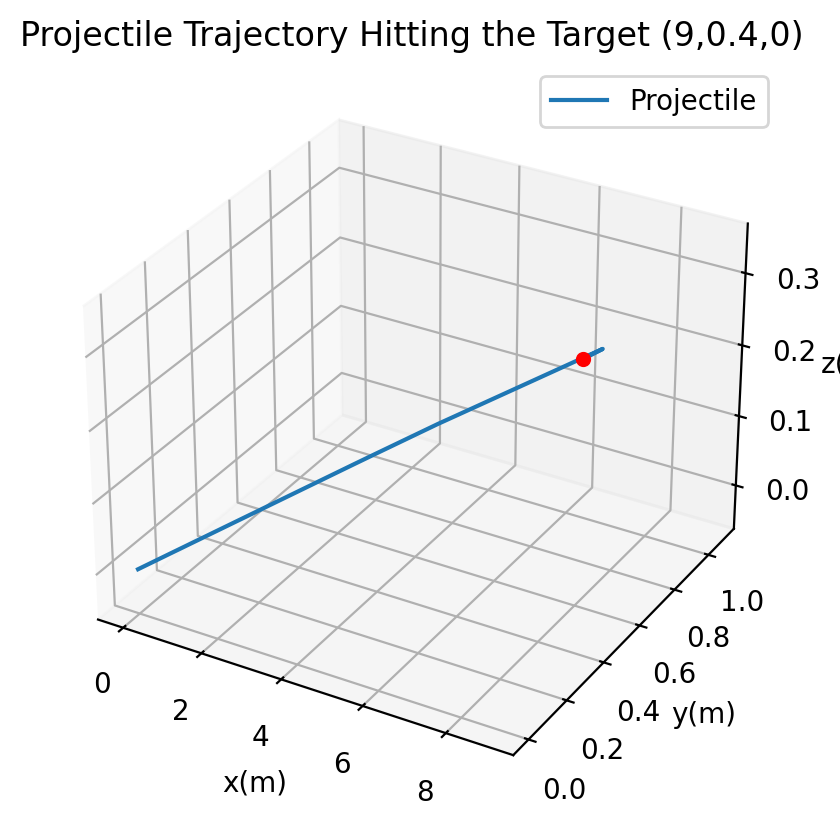

In [ ]:
# Define the constants
g = 9.81 # Gravity
c = 1 # Air resitance coefficient
v0 = 7 # Initial speed
theta = np.pi/4 # Angle of elevation

# Define a function for the moving target
def moving_target(t):
  x = 8 + np.cos(2 * np.pi * t)
  z = np.sin(2 * np.pi * t)
  y = 0.4
  return np.array([x, y, z])

# Define a function that returns the derivatives of the system
# This will compute the derivatives of position and velocity in 3D with air resistance & crosswind
def dy_dt1(t,y):
  x_pos, y_pos, z_pos, x_vel, y_vel, z_vel = y

  # Derivatives of positions
  dxdt = x_vel
  dydt = y_vel
  dzdt = z_vel
  # Derivatives of velocities
  dxv_dt = -c * x_vel
  dyv_dt = -c * y_vel - g
  dzv_dt = -c * (z_vel - 1)
  return [dxdt, dydt, dzdt, dxv_dt, dyv_dt, dzv_dt]


# Define a function to determine the initial 3D velocity components
def initial_v(phi):
  vxi = v0 * np.cos(theta) * np.cos(phi) # x velocity component
  vyi = v0 * np.sin(theta) # y velocity component
  vzi = v0 * np.cos(theta) * np.sin(phi) # z velocity component
  return [vxi, vyi, vzi]


#  Adjusted function that now outputs the difference between the projectile position and the moving target
def target_3d(vector):
  phi, tboost1, tfinal = vector

  # Define the initial state consisting of the projectiles position and velocity at t0
  initial_state = [0,0,0] + initial_v(phi)
  t0 = 0

  # Integrate from the start up until the boost (before tboost)
  initial_solution = solve_ivp(dy_dt1, [t0, tboost1], initial_state)

  # Extract both the position and velocity at the time of the boost (tboost)
  # -1 index extracts the last value
  x_pos1 = initial_solution.y[0,-1] # x position at tboost
  y_pos1 = initial_solution.y[1,-1] # y position at tboost
  z_pos1 = initial_solution.y[2,-1] # z position at tboost
  x_vel1 = initial_solution.y[3,-1] # x velocity at tboost
  y_vel1 = initial_solution.y[4,-1] # y velocity at tboost
  z_vel1 = initial_solution.y[5,-1] # z velocity at tboost

  # Increase the speed to 15 m/s (apply the boost)
  original_speed = np.sqrt(x_vel1**2 + y_vel1**2 + z_vel1**2)
  scale_factor = 15 / original_speed # Maintains direction
  vx_boost = scale_factor * x_vel1
  vy_boost = scale_factor * y_vel1
  vz_boost = scale_factor * z_vel1

  # Update the initial conditions to account for the boost
  new_ic = [x_pos1, y_pos1, z_pos1, vx_boost, vy_boost, vz_boost]

  # Integrate from tboost to tend
  boosted_solution = solve_ivp(dy_dt1, [tboost1, tfinal], new_ic)

  # Extract each component positions at tfinal
  x_pos2 = boosted_solution.y[0,-1]
  y_pos2 = boosted_solution.y[1,-1]
  z_pos2 = boosted_solution.y[2,-1]

  # Compute the difference between the projectile and the moving target at tfinal
  target_pos = moving_target(tfinal)
  return np.array([x_pos2, y_pos2, z_pos2]) - target_pos


# Solve for the system
# That is find phi, tboost1 and tf values which causes the projectile to hit the target
# Make an initial guess for each input
guess = [0.1,0.5,2.5]
solved = root(target_3d, guess)
# Exctract these solutions
phi = solved.x[0]
tboost1 = solved.x[1]
tfinal = solved.x[2]

# Print results
print("The value of the horizontal angle phi which is needed to hit the moving target is:" , phi)
print("The time to boost the projectile in order to hit the moving target is:", tboost1)
print("The time at which the projectile hits the movingtarget is:", tfinal)

# From 0 to tboost1
initial_state = [0,0,0] + initial_v(phi)
initial_solution = solve_ivp(dy_dt1, [0, tboost1], initial_state)


# Extract both the position and velocity at the time of the boost (tboost)
# -1 index extracts the last value
x_pos1 = initial_solution.y[0,-1] # x position at tboost
y_pos1 = initial_solution.y[1,-1] # y position at tboost
z_pos1 = initial_solution.y[2,-1] # z position at tboost
x_vel1 = initial_solution.y[3,-1] # x velocity at tboost
y_vel1 = initial_solution.y[4,-1] # y velocity at tboost
z_vel1 = initial_solution.y[5,-1] # z velocity at tboost

# Increase the speed to 15 m/s (apply the boost)
original_speed = np.sqrt(x_vel1**2 + y_vel1**2 + z_vel1**2)
scale_factor = 15 / original_speed # Maintains direction
vx_boost = scale_factor * x_vel1
vy_boost = scale_factor * y_vel1
vz_boost = scale_factor * z_vel1

# Update the initial conditions to account for the boost
new_ic = [x_pos1, y_pos1, z_pos1, vx_boost, vy_boost, vz_boost]

# Integrate from tboost to tend
boosted_solution = solve_ivp(dy_dt1, [tboost1, tfinal], new_ic)

# Extract each component positions at tfinal
x_pos2 = boosted_solution.y[0,-1]
y_pos2 = boosted_solution.y[1,-1]
z_pos2 = boosted_solution.y[2,-1]

# Combine both trajectories
combine_x = np.concatenate((initial_solution.y[0], boosted_solution.y[0]))
combine_y = np.concatenate((initial_solution.y[1], boosted_solution.y[1]))
combine_z = np.concatenate((initial_solution.y[2], boosted_solution.y[2]))


# Plot the entire 3D trajectory
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(combine_x, combine_y, combine_z, label = 'Projectile')
ax.set_xlabel('x(m)')
ax.set_ylabel('y(m)')
ax.set_zlabel('z(m)')
ax.set_title(f'Projectile Trajectory Hitting the Target (9,0.4,0)')
ax.legend()

# Highlight the moving target on the plot
ax.scatter(*moving_target(tfinal), color = 'red', label ='Moving Target' )
plt.show()




